i need to create a code for my python exam. the question is as follows: 
In a reactor the reaction A + B gives C reaches equilibrium. 
Initial concentration are A0 = 1.5, B0 = 1.0, C0 = 0 mol/L. If x mol?L of C is formed, kc = x/ ((1.5 - x)(1 - x)), 
which rearranges to the quadratic equation kc.x^2 - (2.5kc + 1).x + 1.5kc = 0. 
Write a python program that: 
1. reads kc using input(), prints the data type of the raw input and of the converted value, shows a clear message (no crash) if the text is not a number or if kc<= 0. 
2. finds a, b, c, the discriminant and both roots. 
3. selects the physically meaningful root (0 <= x <= 1, because B is limiting). 
4. prints equilibrium [A], [B], [C] (3decimals) and the conversion of the limiting reactant B = x/ B0 * 100 (%). 
5. classifies the conversion using if/ elif/ else: >= 70% "High", >= 40% "Moderate", otherwise "Low". 

I am a beginner so give the code accordingly and please do not use any library like import math import pandas, etc.

In [ ]:
#Q.1 EQUILIBRIUM CONVERSION CHECKER


raw_kc = input("Enter the equilibrium constant Kc: ")
print("The kc entered is:", raw_kc)
print("The type of kc entered is:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Error: Please enter a valid number for Kc.")
else:
    print("Converted value type:", type(kc))

    if kc <= 0:
        print("Error: Kc must be greater than 0.")
    else:
        # Coefficients of: a*x^2 + b*x + c = 0
        a = kc
        b = -(2.5 * kc + 1)
        c = 1.5 * kc

        discriminant = b**2 - 4 * a * c

        print("a =", a)
        print("b =", b)
        print("c =", c)
        print("Discriminant =", discriminant)

        if discriminant < 0:
            print("There are no real roots.")
        else:
            root1 = (-b + discriminant**0.5) / (2 * a)
            root2 = (-b - discriminant**0.5) / (2 * a)

            print("Root 1 =", root1)
            print("Root 2 =", root2)

            # B is the limiting reactant, so 0 <= x <= 1.
            if 0 <= root1 <= 1:
                x = root1
            elif 0 <= root2 <= 1:
                x = root2
                print("The selected root (x) is:", x)
            else:
                x = None
                print("No root is physically meaningful (0 <= x <= 1).")

            if x is not None:
                A0 = 1.5
                B0 = 1.0

                equilibrium_A = A0 - x
                equilibrium_B = B0 - x
                equilibrium_C = x
                conversion_B = (x / B0) * 100

                print(f"Equilibrium [A] = {equilibrium_A:.3f} mol/L")
                print(f"Equilibrium [B] = {equilibrium_B:.3f} mol/L")
                print(f"Equilibrium [C] = {equilibrium_C:.3f} mol/L")
                print(f"Conversion of B = {conversion_B:.3f}%")

                if conversion_B >= 70:
                    print("Conversion classification: High")
                elif conversion_B >= 40:
                    print("Conversion classification: Moderate")
                else:
                    print("Conversion classification: Low")

The kc entered is: 0.5
The type of kc entered is: <class 'str'>
Converted value type: <class 'float'>
a = 0.5
b = -2.25
c = 0.75
Discriminant = 3.5625
Root 1 = 4.1374586088176875
Root 2 = 0.36254139118231254
The selected root (x) is: 0.36254139118231254
Equilibrium [A] = 1.137 mol/L
Equilibrium [B] = 0.637 mol/L
Equilibrium [C] = 0.363 mol/L
Conversion of B = 36.254%
Conversion classification: Low


---------------------------------------------------------------------------------------------------------------------------
okayy, use the same pattern as above for the next question: Part A: 
In a batch reactor, reactant A is consumed by a first order reaction, dc/dt = -kC. use euler method: C_new = C_old - k.C_old.dt. Take C0 = 2.5 mol/L, k = 0.04 min^-1, dt = 1 min.
Using a for loop, simulate 12 minutes and print a table of time(min), Concentration (mol/L) and conversion(%).
Using math.exp(), calculate the exact value C0e^(-kt) at 12 min and priont the absolute error of the euler result.
Using a while loop, repeat the simulation until conversion reachges 40% or time reaches 100 min. Print the time needed and the final concentration.

In [ ]:
#Q.2 BATCH REACTOR SIMULATION AND BATCH TRACKING.
#PART A: 


import math

C0 = 2.5
k = 0.04
dt = 1.0

# Euler simulation for 12 minutes
concentration = C0

print("Euler method: 12-minute simulation")
print(f"{'Time (min)':<12}{'Concentration (mol/L)':<25}{'Conversion (%)'}")

# Print the initial values at time 0
conversion = (C0 - concentration) / C0 * 100
print(f"{0:<12}{concentration:<25.3f}{conversion:.2f}")

for time_min in range(1, 13):
    concentration = concentration - k * concentration * dt
    conversion = (C0 - concentration) / C0 * 100
    print(f"{time_min:<12}{concentration:<25.3f}{conversion:.2f}")

euler_result = concentration

# Exact concentration at 12 minutes
exact_result = C0 * math.exp(-k * 12)
absolute_error = abs(exact_result - euler_result)

print("\nAt 12 minutes:")
print(f"Euler concentration: {euler_result:.6f} mol/L")
print(f"Exact concentration: {exact_result:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

# Use a while loop until conversion reaches 40% or time reaches 100 minutes
time_min = 0
concentration = C0
conversion = 0

while conversion < 40 and time_min < 100:
    concentration = concentration - k * concentration * dt
    time_min = time_min + 1
    conversion = (C0 - concentration) / C0 * 100

print("\nWhile-loop result:")
print(f"Time needed: {time_min} min")
print(f"Final concentration: {concentration:.3f} mol/L")
print(f"Conversion: {conversion:.2f}%")


Euler method: 12-minute simulation
Time (min)  Concentration (mol/L)    Conversion (%)
0           2.500                    0.00
1           2.400                    4.00
2           2.304                    7.84
3           2.212                    11.53
4           2.123                    15.07
5           2.038                    18.46
6           1.957                    21.72
7           1.879                    24.86
8           1.803                    27.86
9           1.731                    30.75
10          1.662                    33.52
11          1.596                    36.18
12          1.532                    38.73

At 12 minutes:
Euler concentration: 1.531774 mol/L
Exact concentration: 1.546958 mol/L
Absolute error: 0.015184 mol/L

While-loop result:
Time needed: 13 min
Final concentration: 1.471 mol/L
Conversion: 41.18%


-------------------------------------------------------------------------------------------------------------------------------------
Now, Part B: the distillation sample codes such as DIST2026X9Q3 are stored as text. 
Write a program that reads a code, loops through each character, prints the number of digits and the sum of the digits. 
show a message for an empty code and for a code with no digits. 
Test with DIST2026X9Q3, an empty code and ABCDEF. 
Again, for the Part B donot use any library and for part A use only math.exp wherever given.

In [ ]:
#Q.2 EQUILIBRIUM CONVERSION CHECKER (WITH USER INPUT FOR INITIAL CONCENTRATIONS)
# PART B:

code = input("Enter a distillation code: ")

if code == "":
    print("The code is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in code:
        if character in "0123456789":
            digit_count = digit_count + 1
            digit_sum = digit_sum + int(character)

    if digit_count == 0:
        print("The code contains no digits.")
    else:
        print("Number of digits:", digit_count)
        print("Sum of digits:", digit_sum)

Number of digits: 6
Sum of digits: 22


------------------------------------------------------------------------------------------------------------------------------------------------------
The next question:PART A: 
A laboratory has n candidate solvents and wants to test r of them together in a mixed solvent (order doesnot matter). 
Write a recursive function factorial(n) (remember the base case for 0!) and a fucntion combination (n,r) = n!/ (r! (n- r)!) that uses it. 
Reject invalid input (negative values, r> n). Print the number of possible mixtures for n = 9, r = 3, and show the message for n = 6, r 8.

In [ ]:
#Q.3 Solvent screening and sampling schedule
#PART A:


def factorial(number):
    if number < 0:
        return None
    if number == 0:
        return 1
    return number * factorial(number - 1)


def combination(n, r):
    if n < 0 or r < 0 or r > n:
        return None

    return factorial(n) // (factorial(r) * factorial(n - r))


n = 9
r = 3
answer = combination(n, r)

if answer is None:
    print("Invalid input.")
else:
    print(f"Number of mixtures for n = {n}, r = {r}: {answer}")

n = 6
r = 8
answer = combination(n, r)

if answer is None:
    print(f"Invalid input: r ({r}) must not be greater than n ({n}).")
else:
    print(f"Number of mixtures for n = {n}, r = {r}: {answer}")




Number of mixtures for n = 9, r = 3: 84
Invalid input: r (8) must not be greater than n (6).


------------------------------------------------------------------------------------------------------------------------------------------------------
During a crystallisation run, samples are taken at times = Fibonacci number * 4 min. 
Write an iterative fucntion fib_iter(n) that returns a list of the first n Fibonacci numbers, and a recursive function fib_rec(k) that returns the kth Fibonacci number (Fo = 0, F1 = 1).
For n = 10, check that both functions agree and print a table: 
Sample no. | Fibonacci tag | Sampling time (min).
The same goes for this question. Donot use any library.

In [ ]:
#Q.3 Solvent screening and sampling schedule
#PART B:


def fib_iter(n):
    numbers = []
    first = 0
    second = 1

    for _ in range(n):
        numbers.append(first)
        next_number = first + second
        first = second
        second = next_number

    return numbers


def fib_rec(k):
    if k < 0:
        return None
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
iterative_numbers = fib_iter(n)
recursive_numbers = []

for index in range(n):
    recursive_numbers.append(fib_rec(index))

if iterative_numbers == recursive_numbers:
    print("The iterative and recursive Fibonacci functions agree.")
else:
    print("The Fibonacci functions do not agree.")

print(f"{'Sample no.':<12}{'Fibonacci tag':<16}{'Sampling time (min)'}")

for index in range(n):
    fibonacci_tag = iterative_numbers[index]
    sampling_time = fibonacci_tag * 4
    print(f"{index + 1:<12}{fibonacci_tag:<16}{sampling_time}")

The iterative and recursive Fibonacci functions agree.
Sample no.  Fibonacci tag   Sampling time (min)
1           0               0
2           1               4
3           1               4
4           2               8
5           3               12
6           5               20
7           8               32
8           13              52
9           21              84
10          34              136


------------------------------------------------------------------------------------------------------------------------------------------------------
Now for the last question, I can't write the whole question as it contains a table so i will explain it simply. The question has given a kinetics and gas data which we have to solve using pandas and matplotlib. 
So basically a table is given which has the heading: CONSUMPTION OF A REACTANT WAS STUDIED IN A BATCH REACTOR WITH TWO FEED CONCENTRATIONS OF CATALYST. THE CONCENTRATION (MOL/L) WAS RECORDED:And then the table is given which contains columns TIME(min) | Run1_mol_L (low catalyst) | Run2_mol_L (high catalyst). 
The time section is starting form 0 mins and going to 50 mins with a gap of 10 mins. and the second column has the following values 1.50, 1.17, 0.91, 0.71, 0.55 and 0.43. And the third column contains the values 1.50, 0.96, 0.61, 0.39, 0.25 and 0.16.Now what we have to do in this question is 
1. Create a DataFrame from this table. Save it as kinetics.csv (without the index column) and as kinetics.json. Read the CSV back and print its shape and data types.
2. Print the mean and standard deviation of Run1 and Run2, and state which run shows more variation.
3. Plot both runs on one graph (Time on x-axis) with title, axis labels with units, legend and grid.
4. Ethylene gas is compressed slowly in a piston- cylinder at constant temperature: (the table is a s follows): Volume_L column contains 1, 2, 3, 4 and 5 and the Pressure_bar column contains 5.03, 2.52, 1.65, 1,26 and 1.01 values. Plot pressure vs volume as a scatter plot. Calculate k as the mean of P * V and draw the reference curve P= k/V on the same graph. Add title, labels with units and legend.

CSV shape: (6, 3)
CSV data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Kinetics statistics:
Run 1 mean: 0.878 mol/L
Run 1 standard deviation: 0.402 mol/L
Run 2 mean: 0.645 mol/L
Run 2 standard deviation: 0.507 mol/L
Run 2 shows more variation.


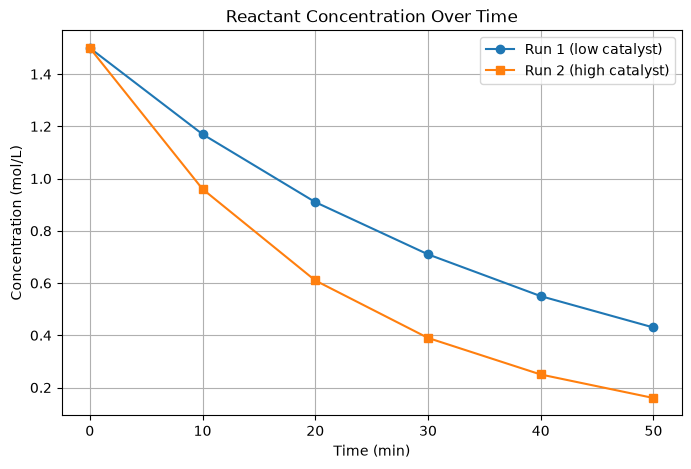


Mean value of P * V (k): 5.022 bar·L


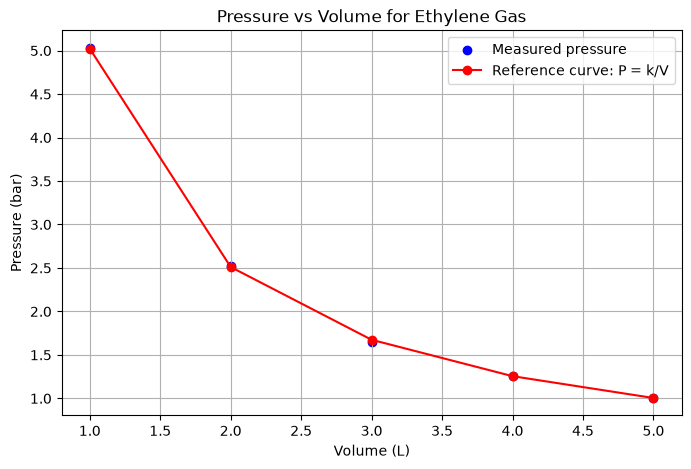

In [ ]:
#Q.4 Kinetics and gas data: pandas and matplotlib



import pandas as pd
import matplotlib.pyplot as plt

# Part 1: Create and save the kinetics DataFrame
kinetics_data = {
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
    "Run2_mol_L": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16]
}

kinetics_df = pd.DataFrame(kinetics_data)

kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=4)

# Read the CSV back and display its shape and data types
kinetics_from_csv = pd.read_csv("kinetics.csv")

print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)


# Part 2: Calculate and compare mean and standard deviation
run1_mean = kinetics_from_csv["Run1_mol_L"].mean()
run1_std = kinetics_from_csv["Run1_mol_L"].std()

run2_mean = kinetics_from_csv["Run2_mol_L"].mean()
run2_std = kinetics_from_csv["Run2_mol_L"].std()

print("\nKinetics statistics:")
print(f"Run 1 mean: {run1_mean:.3f} mol/L")
print(f"Run 1 standard deviation: {run1_std:.3f} mol/L")
print(f"Run 2 mean: {run2_mean:.3f} mol/L")
print(f"Run 2 standard deviation: {run2_std:.3f} mol/L")

if run1_std > run2_std:
    print("Run 1 shows more variation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")


# Part 3: Plot both kinetics runs
plt.figure(figsize=(8, 5))
plt.plot(
    kinetics_from_csv["Time_min"],
    kinetics_from_csv["Run1_mol_L"],
    marker="o",
    label="Run 1 (low catalyst)"
)
plt.plot(
    kinetics_from_csv["Time_min"],
    kinetics_from_csv["Run2_mol_L"],
    marker="s",
    label="Run 2 (high catalyst)"
)

plt.title("Reactant Concentration Over Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.show()


# Part 4: Pressure and volume data
gas_data = {
    "Volume_L": [1, 2, 3, 4, 5],
    "Pressure_bar": [5.03, 2.52, 1.65, 1.26, 1.01]
}

gas_df = pd.DataFrame(gas_data)

# Calculate k as the mean of pressure multiplied by volume
gas_df["P_times_V"] = gas_df["Pressure_bar"] * gas_df["Volume_L"]
k = gas_df["P_times_V"].mean()

print(f"\nMean value of P * V (k): {k:.3f} bar·L")

# Calculate the reference pressure values using P = k / V
reference_pressure = k / gas_df["Volume_L"]

plt.figure(figsize=(8, 5))
plt.scatter(
    gas_df["Volume_L"],
    gas_df["Pressure_bar"],
    label="Measured pressure",
    color="blue"
)
plt.plot(
    gas_df["Volume_L"],
    reference_pressure,
    label="Reference curve: P = k/V",
    color="red",
    marker="o"
)

plt.title("Pressure vs Volume for Ethylene Gas")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.show()